
# Generate Your Own Pixel-Art Sprite

Experiment with a tiny text-conditioned diffusion model and watch your pixel art emerge from random noise!

## How to Use

1. **Choose a prompt** in the Settings cell.
2. **Run the generation cell** to create your sprite.
3. **Run the viewer cell** to explore the denoising process step by step.

## Runtime

- **GPU is optional:** The notebook automatically detects available hardware. CPU works too, just slower.
- **For faster generation:** Go to `Runtime → Change runtime type → T4 GPU`.
- **No login or API key required!**

[View the model on Hugging Face](https://huggingface.co/Tobyz11/toy-pixelart-ddpm)

> **Note:** This is a small educational diffusion model, not a production-grade image generator. Results may vary!




## Setup & Load Model

This section installs the required Python libraries and loads the pretrained pixel-art diffusion model from [Hugging Face](https://huggingface.co/Tobyz11/toy-pixelart-ddpm).

### ⚙️ Settings

- **MODEL_REPO:** Hugging Face repository containing the model.
- **MODEL_REVISION:** Model version or branch (`main` by default).
- **FORCE_CPU:** Enable to run on CPU even if a GPU is available.

### 🔍 What happens?

1. Install the required dependencies.
2. Download the model weights, configuration, and architecture.
3. Load the pretrained CLIP text encoder to understand your prompts.
4. Initialize the diffusion model for sprite generation.
5. Automatically select GPU or CPU.

**No Hugging Face login required** The model is publicly accessible.

In [1]:
# @title Install dependencies
%pip install -q "transformers>=5,<6" "huggingface_hub>=1.25.1,<2" safetensors Pillow numpy matplotlib tqdm

In [2]:
# @title Load the public model
MODEL_REPO = "Tobyz11/toy-pixelart-ddpm" # @param {type:"string"}
MODEL_REVISION = "main" # @param {type:"string"}
FORCE_CPU = False # @param {type:"boolean"}

import gc, json, math, importlib.util
from pathlib import Path
import numpy as np
import torch
import matplotlib.pyplot as plt
from PIL import Image
from huggingface_hub import snapshot_download
from safetensors.torch import load_file
from transformers import CLIPTokenizerFast, CLIPTextModel
from IPython.display import display, HTML, FileLink
from tqdm.auto import tqdm

# Load the code and weights from your public model repo.
folder = Path(snapshot_download(MODEL_REPO, revision=MODEL_REVISION, token=False,
    allow_patterns=['config.json', 'model.safetensors', 'pixelart_ddpm.py']))
spec = importlib.util.spec_from_file_location('pixelart_ddpm', folder / 'pixelart_ddpm.py')
p = importlib.util.module_from_spec(spec)
spec.loader.exec_module(p)
config = json.loads((folder / 'config.json').read_text())
provenance = config['provenance']
device = torch.device('cuda' if torch.cuda.is_available() and not FORCE_CPU else 'cpu')
bf16 = device.type == 'cuda' and torch.cuda.is_bf16_supported()

# Release the previous models if you rerun this cell.
for name in ('model', 'encoder', 'diffusion', 'hidden', 'mask', 'null_hidden', 'null_mask'):
    globals().pop(name, None)
gc.collect()
if device.type == 'cuda':
    torch.cuda.empty_cache()

model = p.TextUNet(**config['model_config']).eval().requires_grad_(False)
model.load_state_dict(load_file(str(folder / 'model.safetensors')))
model = model.to(device, memory_format=torch.channels_last)
clip_args = dict(revision=provenance['text_encoder_revision'], token=False)
tokenizer = CLIPTokenizerFast.from_pretrained(provenance['text_encoder_id'], **clip_args)
encoder = CLIPTextModel.from_pretrained(provenance['text_encoder_id'], **clip_args,
    dtype=torch.bfloat16 if bf16 else torch.float32).to(device).eval().requires_grad_(False)
diffusion = p.Diffusion(**config['diffusion_config'], device=device)

@torch.no_grad()
def encode(prompts):
    tokens = tokenizer(prompts, padding='max_length', truncation=True,
        max_length=provenance['max_text_length'], return_tensors='pt')
    return p.encode_text_batch(encoder, tokens['input_ids'], tokens['attention_mask'], device, bf16)

print('Ready on', device, '·', 'BF16' if bf16 else 'float32')

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 3 files:   0%|          | 0/3 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/905 [00:00<?, ?B/s]

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


vocab.json:   0%|          | 0.00/961k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/525k [00:00<?, ?B/s]

... (4 outputs left out)

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

[transformers] CLIPTextModel LOAD REPORT from: openai/clip-vit-large-patch14
Key                                                            | Status     |  | 
---------------------------------------------------------------+------------+--+-
vision_model.encoder.layers.{0...23}.self_attn.v_proj.bias     | UNEXPECTED |  | 
vision_model.encoder.layers.{0...23}.self_attn.out_proj.weight | UNEXPECTED |  | 
vision_model.encoder.layers.{0...23}.self_attn.q_proj.bias     | UNEXPECTED |  | 
text_projection.weight                                         | UNEXPECTED |  | 
vision_model.encoder.layers.{0...23}.self_attn.k_proj.bias     | UNEXPECTED |  | 
vision_model.encoder.layers.{0...23}.mlp.fc2.bias              | UNEXPECTED |  | 
vision_model.encoder.layers.{0...23}.self_attn.out_proj.bias   | UNEXPECTED |  | 
vision_model.encoder.layers.{0...23}.mlp.fc1.bias              | UNEXPECTED |  | 
vision_model.encoder.layers.{0...23}.layer_norm1.bias          | UNEXPECTED |  | 
vision_model.encoder.

Ready on cuda · BF16


## Try a prompt
Edit the settings below, run the generation cell, then run the viewer cell. To try another sprite, repeat from here; the model stays loaded.

Parameters:
- **Prompt:** Describe what you want to generate.
- **Seed:** Change for different results.
- **Sampler:** `ddim` (recommended) or `ddpm`.
- **Steps:** Number of denoising steps (try 50).
- **Guidance:** How strongly the model follows your prompt (try 4.0).
- **DDIM Eta:** Controls randomness (`0.0` = deterministic).
- **Live Preview:** Watch the denoising process in real time.

In [ ]:
# @title What would you like to generate?
PROMPT = "pixel art icon of alfajores with chocola" # @param {type:"string"}
SEED = 123 # @param {type:"integer"}
SAMPLER = "ddim" # @param ["ddim", "ddpm"]
STEPS = 50 # @param {type:"integer"}
GUIDANCE = 4.0 # @param {type:"number"}
DDIM_ETA = 0.0 # @param {type:"number"}
LIVE_PREVIEW = True # @param {type:"boolean"}
PREVIEW_FRAMES = STEPS

In [57]:
# @title Generate the sprite
def generate_sprite(PROMPT, SEED, SAMPLER, STEPS, GUIDANCE, DDIM_ETA, LIVE_PREVIEW=True):
    if not isinstance(SEED, int) or not 0 <= SEED <= 2**32 - 1:
        raise ValueError('Seed must be an integer between 0 and 4294967295.')
    PREVIEW_FRAMES = STEPS
    if not PROMPT.strip() or SAMPLER not in ('ddim', 'ddpm'):
        raise ValueError('Enter a prompt and choose ddim or ddpm.')
    if not isinstance(STEPS, int) or not 2 <= STEPS <= diffusion.timesteps:
        raise ValueError(f'STEPS must be between 2 and {diffusion.timesteps}.')
    if not isinstance(PREVIEW_FRAMES, int) or PREVIEW_FRAMES < 1:
        raise ValueError('PREVIEW_FRAMES must be at least 1.')
    if not math.isfinite(GUIDANCE) or not math.isfinite(DDIM_ETA) or DDIM_ETA < 0:
        raise ValueError('Use finite guidance and a nonnegative, finite eta.')

    p.seed_everything(SEED)
    hidden, mask = encode([PROMPT])
    null_hidden, null_mask = encode([''])
    rng = torch.Generator(device=device).manual_seed(SEED)
    x = torch.randn((1, 4, 32, 32), generator=rng, device=device)
    indices = torch.linspace(diffusion.timesteps - 1, 0, STEPS, device=device).round().long().tolist()
    record_at = set(np.linspace(0, STEPS - 1, min(PREVIEW_FRAMES, STEPS)).round().astype(int))
    reverse_frames = [('initial noise', x.cpu())]
    preview = display(HTML('Starting from noise…'), display_id=True) if LIVE_PREVIEW else None
    status = display(HTML(''), display_id=True) if LIVE_PREVIEW else None

    with torch.no_grad():
        for i, index in enumerate(tqdm(indices, desc='Denoising')):
            t = torch.full((1,), index, device=device, dtype=torch.long)
            with p.amp_context(device, bf16):
                if GUIDANCE == 1.0:
                    predicted = model(x, t, hidden, mask)
                else:
                    unconditioned = model(x, t, null_hidden, null_mask)
                    predicted = unconditioned + GUIDANCE * (model(x, t, hidden, mask) - unconditioned)
            noise = torch.randn(x.shape, generator=rng, device=device)
            previous = torch.full_like(t, indices[i + 1] if i + 1 < STEPS else -1)
            if SAMPLER == 'ddpm':
                x = diffusion.ddpm_step(x, t, predicted.float(), noise, previous)
            else:
                x = diffusion.ddim_step(x, t, previous, predicted.float(), noise, DDIM_ETA)
            if not torch.isfinite(x).all():
                raise FloatingPointError(f'Non-finite sample at timestep {index}.')
            if i in record_at:
                reverse_frames.append((f't={index}', x.cpu()))
                if preview is not None and ((i + 1) % max(1, STEPS // 24) == 0 or i + 1 == STEPS):
                    preview.update(p.checkerboard(p.tensor_to_rgba(x[0]), scale=8))
                    status.update(HTML(f'Step {i + 1}/{STEPS}'))

    sprite = p.tensor_to_rgba(x[0])

    return sprite, reverse_frames

current_settings = dict(PROMPT=PROMPT, SEED=SEED, SAMPLER=SAMPLER, STEPS=STEPS,
    GUIDANCE=GUIDANCE, DDIM_ETA=DDIM_ETA, LIVE_PREVIEW=LIVE_PREVIEW)
sprite, reverse_frames = generate_sprite(**current_settings)

Denoising:   0%|          | 0/50 [00:00<?, ?it/s]


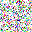
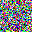
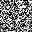
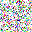
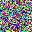
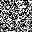
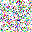
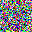
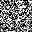
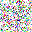
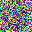
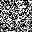
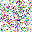
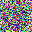
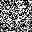
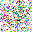
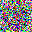
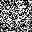
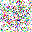
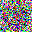
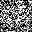
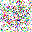
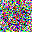
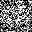
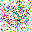
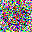
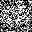
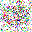
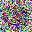
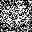
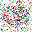
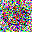
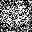
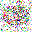
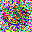
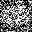
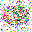
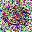
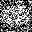
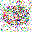
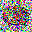
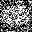
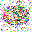
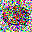
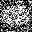
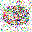
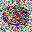
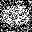
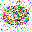
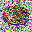
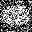
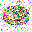
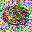
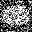
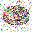
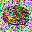
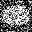
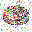
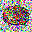
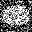
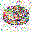
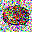
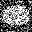
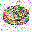
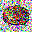
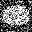
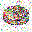
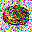
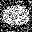
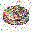
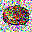
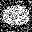
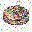
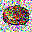
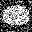
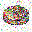
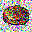
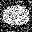
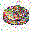
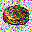
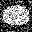
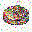
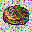
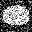
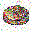
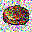
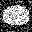
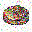
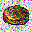
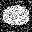
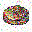
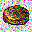
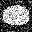
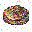
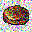
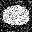
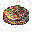
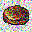
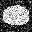
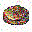
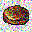
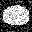
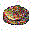
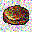
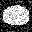
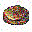
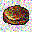
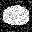
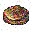
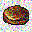
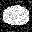
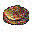
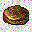
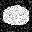
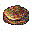
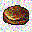
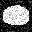
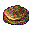
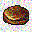
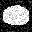
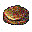
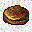
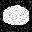
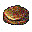
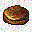
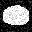
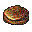
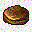
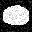
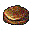
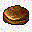
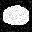
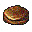
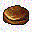
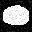
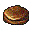
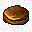
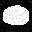
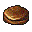
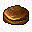
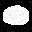
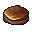
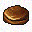
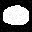
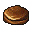
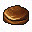
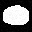
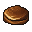
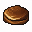
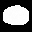
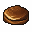
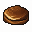
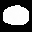

In [58]:
# @title Explore the denoising player
"""A self-contained diffusion player for notebook output and saved HTML."""
import base64
import html
import io
import json
import uuid


def diffusion_viewer(images, labels, prompt, details):
    """Embed RGBA, RGB and alpha frames so playback never needs the Python kernel."""
    def png(image):
        buffer = io.BytesIO()
        image.save(buffer, format='PNG')
        return 'data:image/png;base64,' + base64.b64encode(buffer.getvalue()).decode()

    frames = [dict(rgba=png(image), rgb=png(image.convert('RGB')),
                   alpha=png(image.getchannel('A').convert('RGB')), label=label)
              for image, label in zip(images, labels)]
    if not frames:
        raise ValueError('Generate at least one frame first.')
    uid = 'diffusion-' + uuid.uuid4().hex
    payload = json.dumps(frames).replace('<', '\\u003c')
    template = r'''
<section id="__ID__" tabindex="0" aria-label="Diffusion player">
<style>
#__ID__ {font:14px/1.5 system-ui,sans-serif;background:#101827;color:#e8eef9;padding:24px;border-radius:20px;max-width:920px;box-sizing:border-box;outline-offset:4px}
#__ID__ * {box-sizing:border-box}
#__ID__ h2 {font-size:22px;margin:4px 0 6px;color:#fff} #__ID__ p {margin:0 0 18px;color:#abbad0}
#__ID__ .eyebrow {color:#6ee7cf;font-size:11px;font-weight:700;letter-spacing:2px}
#__ID__ .screens {display:grid;grid-template-columns:2fr 1fr;gap:16px;align-items:start}
#__ID__ .well {background-color:#e2e8f0;background-image:conic-gradient(#cbd5e1 25%,transparent 0 50%,#cbd5e1 0 75%,transparent 0);background-size:24px 24px;border:1px solid #435065;border-radius:12px;overflow:hidden}
#__ID__ .well img {display:block;width:100%;aspect-ratio:1;image-rendering:pixelated;object-fit:contain}
#__ID__ .caption {display:flex;justify-content:space-between;gap:8px;margin:8px 0;color:#b9c8dd;font-size:12px}
#__ID__ button, #__ID__ select {font:inherit;color:#e8eef9;background:#243247;border:1px solid #435065;border-radius:8px;padding:7px 11px;cursor:pointer}
#__ID__ button:hover {background:#344860} #__ID__ button:disabled {opacity:.4;cursor:default}
#__ID__ button:focus-visible, #__ID__ select:focus-visible {outline:2px solid #6ee7cf;outline-offset:2px}
#__ID__ .play {background:#6ee7cf;color:#102c2b;min-width:90px;font-weight:700}
#__ID__ .controls {display:flex;gap:8px;align-items:center;flex-wrap:wrap;margin:12px 0}
#__ID__ .timeline {width:100%;accent-color:#6ee7cf;cursor:pointer;margin:10px 0}
#__ID__ .ends {display:flex;justify-content:space-between;color:#abbad0;font-size:12px}
#__ID__ .strip {display:grid;grid-template-columns:repeat(6,minmax(0,1fr));gap:8px;margin-top:16px}
#__ID__ .thumb {padding:5px;font-size:11px;min-width:0} #__ID__ .thumb img {width:100%;image-rendering:pixelated;display:block;margin-bottom:4px}
#__ID__ .thumb[aria-pressed=true] {border-color:#6ee7cf;background:#234441}
#__ID__ .hint {font-size:12px;margin:16px 0 0}
@media(max-width:540px){#__ID__{padding:14px} #__ID__ .screens {grid-template-columns:3fr 2fr;gap:10px} #__ID__ .strip{grid-template-columns:repeat(3,1fr)} #__ID__ .controls{gap:6px}}
</style>
<div class="eyebrow">NOISE → SPRITE</div>
<h2>__PROMPT__</h2><p>__DETAILS__</p>
<div class="screens">
  <div><div class="well stage"><img class="current" alt="Selected diffusion frame"></div><div class="caption"><span class="step"></span><span class="timestep"></span></div></div>
  <div><div class="well stage"><img class="final" alt="Final generated sprite"></div><div class="caption">Final sprite · 32 × 32</div></div>
</div>
<input class="timeline" type="range" min="0" value="0" step="1" aria-label="Denoising timeline">
<div class="ends"><span>Initial noise</span><span>Finished sprite</span></div>
<div class="controls">
  <button class="restart" aria-label="Return to first frame">↶ Start</button>
  <button class="back" aria-label="Previous frame">←</button>
  <button class="play" aria-label="Play denoising">▶ Play</button>
  <button class="next" aria-label="Next frame">→</button>
  <label>Speed <select class="speed" aria-label="Playback speed"><option value="4">4 fps</option><option value="8" selected>8 fps</option><option value="16">16 fps</option><option value="24">24 fps</option></select></label>
  <label><input class="loop" type="checkbox"> Loop</label>
  <label>View <select class="view" aria-label="Image view"><option value="rgba">Transparency</option><option value="white">White background</option><option value="dark">Dark background</option><option value="rgb">RGB only</option><option value="alpha">Alpha mask</option></select></label>
</div>
<div class="strip" aria-label="Jump to a stage"></div>
<p class="hint">Drag the timeline or press Play. Focus the player and use ← / → to step, Space to play.
Frames show the actual noisy sample, clipped for display. Alpha: white is opaque, black is transparent.</p>
<noscript>This viewer needs JavaScript. Open diffusion.gif for an animation.</noscript>
<script>
(() => {
 const root=document.getElementById('__ID__'), frames=__FRAMES__;
 const q=s=>root.querySelector(s), slider=q('.timeline'), play=q('.play');
 const last=frames.length-1; slider.max=last;
 let index=0, timer=null;
 const thumbs=[];
 function source(frame){const view=q('.view').value;return frame[view==='alpha'?'alpha':view==='rgb'?'rgb':'rgba'];}
 function render(){
   slider.value=index;q('.current').src=source(frames[index]);q('.final').src=source(frames[last]);
   q('.step').textContent=`Step ${index} / ${last}`;q('.timestep').textContent=frames[index].label;
   q('.back').disabled=index===0;q('.next').disabled=index===last;
   root.querySelectorAll('.stage').forEach(el=>{const view=q('.view').value;
     el.style.backgroundImage=view==='rgba'?'':'none';
     el.style.backgroundColor=view==='white'?'#fff':view==='dark'?'#17202e':'#e2e8f0';});
   thumbs.forEach(({button,img,i})=>{img.src=source(frames[i]);button.setAttribute('aria-pressed',String(i===index));});
 }
 function stop(){clearInterval(timer);timer=null;play.textContent='▶ Play';play.setAttribute('aria-label','Play denoising');}
 function start(){stop();if(index===last)index=0;render();play.textContent='Ⅱ Pause';play.setAttribute('aria-label','Pause denoising');
   timer=setInterval(()=>{if(!root.isConnected){stop();return;}
     if(index<last){index++;render();if(index===last&&!q('.loop').checked)stop();}
     else if(q('.loop').checked){index=0;render();}else stop();},1000/Number(q('.speed').value));}
 function jump(i){stop();index=Math.max(0,Math.min(last,i));render();}
 play.onclick=()=>timer===null?start():stop();
 slider.oninput=()=>jump(Number(slider.value));q('.restart').onclick=()=>jump(0);
 q('.back').onclick=()=>jump(index-1);q('.next').onclick=()=>jump(index+1);
 q('.view').onchange=render;q('.speed').onchange=()=>{if(timer!==null){stop();start();}};
 root.onkeydown=e=>{if(['INPUT','SELECT','BUTTON'].includes(e.target.tagName))return;
   if(e.key==='ArrowRight'){e.preventDefault();jump(index+1);}if(e.key==='ArrowLeft'){e.preventDefault();jump(index-1);}
   if(e.code==='Space'){e.preventDefault();play.click();}};
 [...new Set(Array.from({length:Math.min(6,frames.length)},(_,n)=>Math.round(n*last/(Math.min(6,frames.length)-1||1))))].forEach(i=>{
   const button=document.createElement('button'),img=document.createElement('img');
   button.className='thumb';button.setAttribute('aria-label',`Jump to step ${i}`);img.alt='';
   button.append(img,document.createTextNode(i===0?'Noise':i===last?'Final':`Step ${i}`));
   button.onclick=()=>jump(i);q('.strip').append(button);thumbs.push({button,img,i});});

 render();
})();
</script></section>'''
    return (template.replace('__ID__', uid).replace('__PROMPT__', html.escape(prompt))
            .replace('__DETAILS__', html.escape(details)).replace('__FRAMES__', payload))


output = Path('/content/sprite-output')
output.mkdir(parents=True, exist_ok=True)

def save_result(sprite, reverse_frames, settings):
    PROMPT, SEED, SAMPLER, STEPS, GUIDANCE, DDIM_ETA = (settings[k] for k in ('PROMPT', 'SEED', 'SAMPLER', 'STEPS', 'GUIDANCE', 'DDIM_ETA'))
    images = [p.tensor_to_rgba(batch[0]) for _, batch in reverse_frames]
    labels = [label for label, _ in reverse_frames]
    details = f'{SAMPLER.upper()} · {STEPS} steps · guidance {GUIDANCE} · seed {SEED} · {device}'
    player_html = diffusion_viewer(images, labels, PROMPT, details)

    # Keep a compact snapshot sheet as well as the full player and animation.
    chosen = np.linspace(0, len(images) - 1, min(6, len(images))).round().astype(int)
    fig, axes = plt.subplots(2, len(chosen), figsize=(len(chosen) * 2, 4), squeeze=False)
    for col, index in enumerate(chosen):
        axes[0, col].imshow(p.checkerboard(images[index]), interpolation='nearest')
        axes[0, col].set_title('Noise' if index == 0 else f'Step {index}', fontsize=9)
        axes[1, col].imshow(images[index].getchannel('A'), cmap='gray', vmin=0, vmax=255)
        axes[1, col].set_title('alpha', fontsize=9)
    for ax in axes.flat:
        ax.axis('off')
    plt.tight_layout()
    fig.savefig(output / 'snapshots.png', dpi=120)
    plt.close(fig)
    animation = [p.checkerboard(image, scale=8) for image in images]
    sprite.save(output / 'sprite.png')
    sprite.resize((320, 320), Image.Resampling.NEAREST).save(output / 'sprite_10x.png')
    animation[0].save(output / 'diffusion.gif', save_all=True,
        append_images=animation[1:], duration=125, loop=0)
    (output / 'viewer.html').write_text('<!doctype html><meta charset="utf-8"><meta name="viewport" content="width=device-width, initial-scale=1">' + player_html, encoding='utf-8')
    (output / 'settings.json').write_text(json.dumps(dict(prompt=PROMPT, seed=SEED,
        sampler=SAMPLER, steps=STEPS, guidance=GUIDANCE, ddim_eta=DDIM_ETA,
        model_repo=MODEL_REPO, model_revision=MODEL_REVISION,
        resolved_model_revision=folder.name, device=str(device)), indent=2))

    return player_html

display(HTML(save_result(sprite, reverse_frames, current_settings)))

## Keep your result
Download the transparent sprite, enlarged PNG, GIF, snapshot sheet, settings, and **viewer.html** — the interactive player also works offline.

In [ ]:
# @title Download everything
import shutil
archive = shutil.make_archive(str(output), 'zip', root_dir=output)
try:
    from google.colab import files
except ImportError:
    display(FileLink(archive))
else:
    files.download(archive)